# NYC Taxi Trip Analysis (Automatidata Capstone)

Exploratory data analysis and a hypothesis test on 22,699 NYC Taxi and Limousine Commission (TLC) yellow-taxi trips from 2017.

**Context:** practice capstone for the Google Advanced Data Analytics Professional Certificate (Coursera). The scenario is fictional (a consulting firm, Automatidata, analysing TLC trip data); the dataset is the course-provided sample.

**Business question:** do customers who pay by credit card pay higher fares than customers who pay cash?

**Sections:** 1. Load and inspect · 2. Prepare the data · 3. Data quality checks · 4. Exploratory data analysis · 5. Hypothesis test

**To run:** place the course CSV in a `data/` folder as `2017_Yellow_Taxi_Trip_Data.csv`, then run all cells.

## 1. Load and inspect

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

df = pd.read_csv(r"C:\Users\LENOVO\OneDrive\Desktop\Data\Data\2017_Yellow_Taxi_Trip_Data.csv")

In [2]:
df.shape

(22699, 18)

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22699 entries, 0 to 22698
Data columns (total 18 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             22699 non-null  int64  
 1   VendorID               22699 non-null  int64  
 2   tpep_pickup_datetime   22699 non-null  object 
 3   tpep_dropoff_datetime  22699 non-null  object 
 4   passenger_count        22699 non-null  int64  
 5   trip_distance          22699 non-null  float64
 6   RatecodeID             22699 non-null  int64  
 7   store_and_fwd_flag     22699 non-null  object 
 8   PULocationID           22699 non-null  int64  
 9   DOLocationID           22699 non-null  int64  
 10  payment_type           22699 non-null  int64  
 11  fare_amount            22699 non-null  float64
 12  extra                  22699 non-null  float64
 13  mta_tax                22699 non-null  float64
 14  tip_amount             22699 non-null  float64
 15  to

In [5]:
df.isnull().sum()

Unnamed: 0               0
VendorID                 0
tpep_pickup_datetime     0
tpep_dropoff_datetime    0
passenger_count          0
trip_distance            0
RatecodeID               0
store_and_fwd_flag       0
PULocationID             0
DOLocationID             0
payment_type             0
fare_amount              0
extra                    0
mta_tax                  0
tip_amount               0
tolls_amount             0
improvement_surcharge    0
total_amount             0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.describe()

,Unnamed: 0,VendorID,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount
count,2.269900e+04,22699.000000,22699.000000,22699.000000,22699.000000,22699.000000,22699.000000,22699.000000,22699.000000,22699.000000,22699.000000,22699.000000,22699.000000,22699.000000,22699.000000
mean,5.675849e+07,1.556236,1.642319,2.913313,1.043394,162.412353,161.527997,1.336887,13.026629,0.333275,0.497445,1.835781,0.312542,0.299551,16.310502
std,3.274493e+07,0.496838,1.285231,3.653171,0.708391,66.633373,70.139691,0.496211,13.243791,0.463097,0.039465,2.800626,1.399212,0.015673,16.097295
min,1.212700e+04,1.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,-120.000000,-1.000000,-0.500000,0.000000,0.000000,-0.300000,-120.300000
25%,2.852056e+07,1.000000,1.000000,0.990000,1.000000,114.000000,112.000000,1.000000,6.500000,0.000000,0.500000,0.000000,0.000000,0.300000,8.750000
50%,5.673150e+07,2.000000,1.000000,1.610000,1.000000,162.000000,162.000000,1.000000,9.500000,0.000000,0.500000,1.350000,0.000000,0.300000,11.800000
75%,8.537452e+07,2.000000,2.000000,3.060000,1.000000,233.000000,233.000000,2.000000,14.500000,0.500000,0.500000,2.450000,0.000000,0.300000,17.800000
max,1.134863e+08,2.000000,6.000000,33.960000,99.000000,265.000000,265.000000,4.000000,999.990000,4.500000,0.500000,200.000000,19.100000,0.300000,1200.290000


No missing values or duplicate rows. The summary statistics do show data-quality issues, which are handled in section 3: negative fares and totals, trips with zero distance or zero passengers, and a `RatecodeID` maximum of 99 (the valid codes are 1 to 6).

## 2. Prepare the data
Convert the timestamps to datetime, rename the ID column, and create trip duration, month, and day-of-week fields.

In [8]:
df['tpep_pickup_datetime'] = pd.to_datetime(df['tpep_pickup_datetime'])
df['tpep_dropoff_datetime'] = pd.to_datetime(df['tpep_dropoff_datetime'])
df = df.rename(columns={'Unnamed: 0': 'trip_ID'})

df['trip_duration_min'] = (df['tpep_dropoff_datetime'] - df['tpep_pickup_datetime']).dt.total_seconds() / 60
df['month'] = df['tpep_pickup_datetime'].dt.month_name()
df['day'] = df['tpep_pickup_datetime'].dt.day_name()

month_order = ['January', 'February', 'March', 'April', 'May', 'June',
               'July', 'August', 'September', 'October', 'November', 'December']
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
df.dtypes

trip_ID                           int64
VendorID                          int64
tpep_pickup_datetime     datetime64[ns]
tpep_dropoff_datetime    datetime64[ns]
passenger_count                   int64
trip_distance                   float64
RatecodeID                        int64
store_and_fwd_flag               object
PULocationID                      int64
DOLocationID                      int64
payment_type                      int64
fare_amount                     float64
extra                           float64
mta_tax                         float64
tip_amount                      float64
tolls_amount                    float64
improvement_surcharge           float64
total_amount                    float64
trip_duration_min               float64
month                            object
day                              object
dtype: object

## 3. Data quality checks
Count the suspicious records before deciding what to exclude.

In [9]:
issues = {
    'fare_amount <= 0': (df['fare_amount'] <= 0).sum(),
    'trip_distance == 0': (df['trip_distance'] == 0).sum(),
    'passenger_count == 0': (df['passenger_count'] == 0).sum(),
    'RatecodeID not in 1-6': (~df['RatecodeID'].between(1, 6)).sum(),
    'trip_duration_min <= 0': (df['trip_duration_min'] <= 0).sum(),
}
pd.Series(issues, name='records affected')

fare_amount <= 0           20
trip_distance == 0        148
passenger_count == 0       33
RatecodeID not in 1-6       1
trip_duration_min <= 0     27
Name: records affected, dtype: int64

**Cleaning rules:** exclude trips with a non-positive fare, zero distance, zero passengers, or an invalid rate code, since these are not valid completed fares. The exploratory charts in section 4 use the full dataset so the outliers stay visible (the zoomed-in charts handle them); the hypothesis test in section 5 uses the cleaned data.

In [10]:
df_clean = df[
    (df['fare_amount'] > 0)
    & (df['trip_distance'] > 0)
    & (df['passenger_count'] > 0)
    & (df['RatecodeID'].between(1, 6))
].copy()

print(f"Rows before: {len(df):,} | after: {len(df_clean):,} | removed: {len(df) - len(df_clean):,}")

Rows before: 22,699 | after: 22,503 | removed: 196


## 4. Exploratory data analysis

### Trip distance

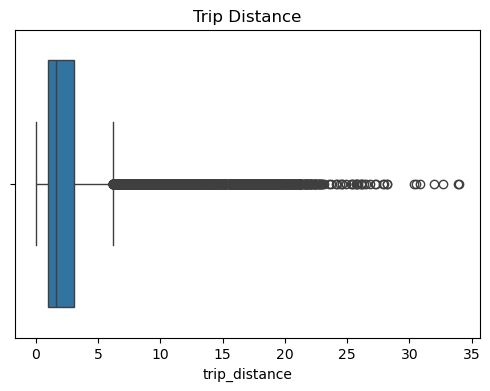

In [11]:
plt.figure(figsize=(6,4))
sns.boxplot(x=df['trip_distance'])
plt.title('Trip Distance')
plt.show()

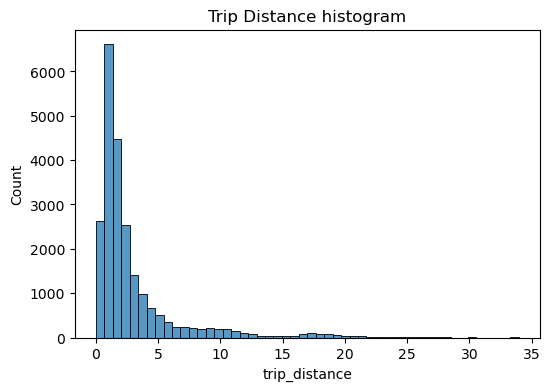

In [12]:
plt.figure(figsize=(6,4))
sns.histplot(df['trip_distance'], bins=50)
plt.title('Trip Distance histogram')
plt.show()

Trips are short and right-skewed: the median is 1.61 miles against a mean of 2.91, with a maximum of 33.96 miles.

### Total amount

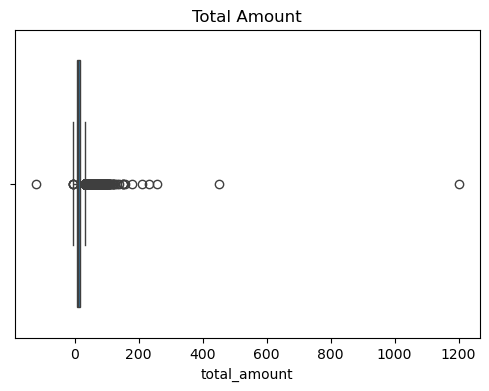

In [13]:
plt.figure(figsize=(6,4))
sns.boxplot(x=df['total_amount'])
plt.title('Total Amount')
plt.show()

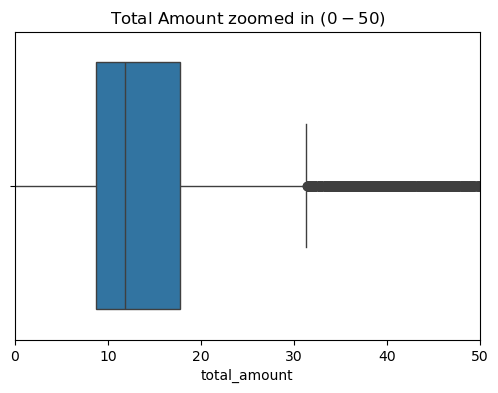

In [14]:
plt.figure(figsize=(6,4))
sns.boxplot(x=df['total_amount'])
plt.xlim(0,50)
plt.title('Total Amount zoomed in ($0-$50)')
plt.show()

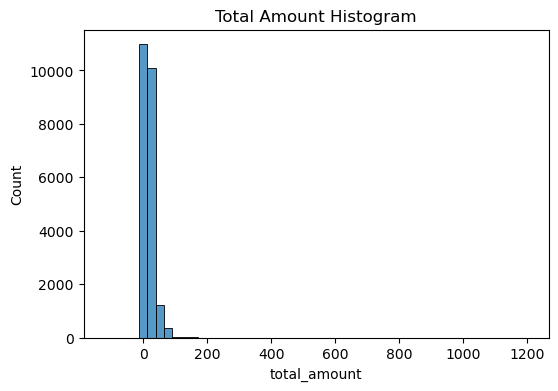

In [15]:
plt.figure(figsize=(6,4))
sns.histplot(df['total_amount'], bins=50)
plt.title('Total Amount Histogram')
plt.show()

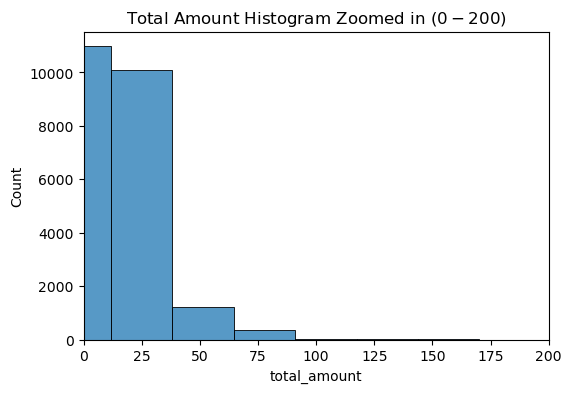

In [16]:
plt.figure(figsize=(6,4))
sns.histplot(df['total_amount'], bins=50)
plt.xlim(0,200)
plt.title('Total Amount Histogram Zoomed in ($0-$200)')
plt.show()

A few extreme values (the maximum is over $1,200) stretch the full-range charts. The median total is $11.80 against a mean of $16.31, so the zoomed charts show the typical fare range better.

### Tip amount

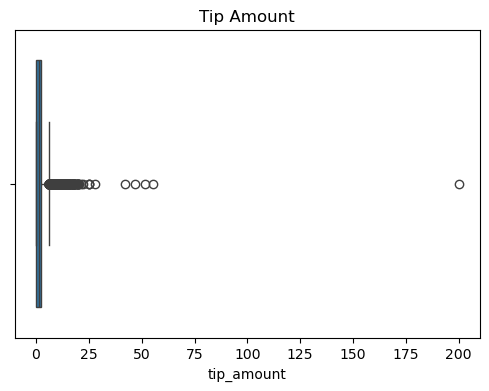

In [17]:
plt.figure(figsize=(6,4))
sns.boxplot(x=df['tip_amount'])
plt.title('Tip Amount')
plt.show()

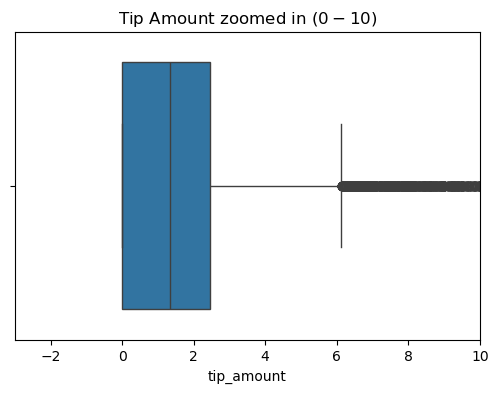

In [18]:
plt.figure(figsize=(6,4))
sns.boxplot(x=df['tip_amount'])
plt.xlim(-3,10)
plt.title('Tip Amount zoomed in ($0-$10)')
plt.show()

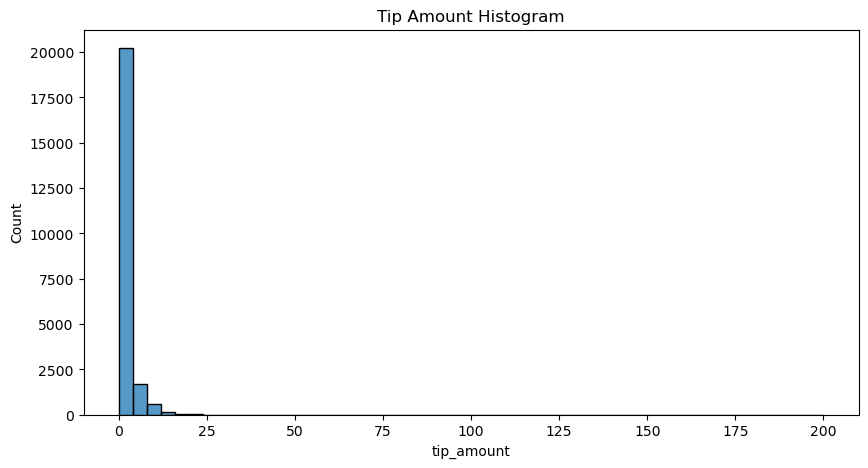

In [19]:
plt.figure(figsize=(10,5))
sns.histplot(df['tip_amount'], bins=50)
plt.title('Tip Amount Histogram')
plt.show()

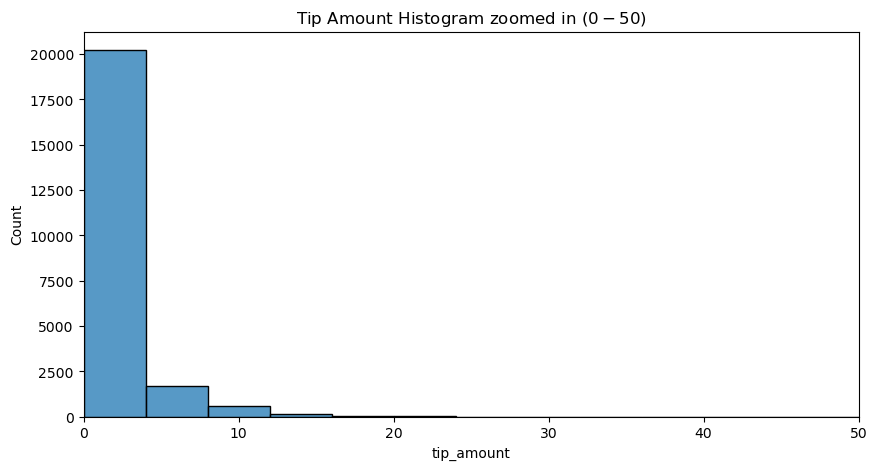

In [20]:
plt.figure(figsize=(10,5))
sns.histplot(df['tip_amount'], bins=50)
plt.xlim(0,50)
plt.title('Tip Amount Histogram zoomed in ($0-$50)')
plt.show()

Tips are heavily right-skewed: the median is $1.35 against a mean of $1.84, and the largest tip is $200.

### Tips by vendor

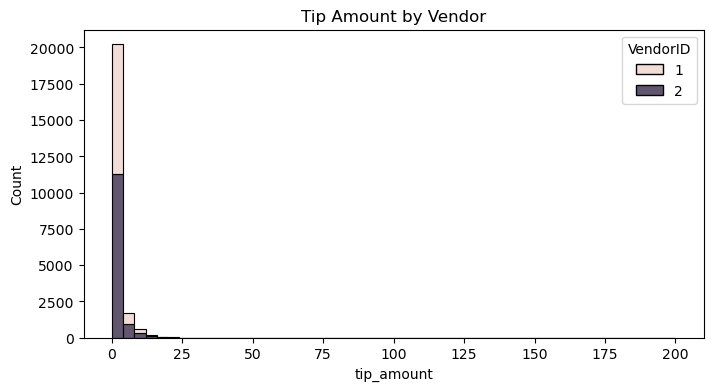

In [21]:
plt.figure(figsize=(8,4))
sns.histplot(data=df, x='tip_amount', hue='VendorID', bins=50, multiple='stack')
plt.title('Tip Amount by Vendor')
plt.show()

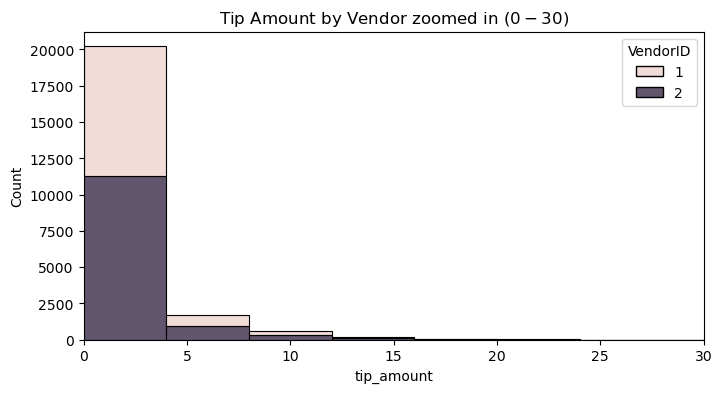

In [22]:
plt.figure(figsize=(8,4))
sns.histplot(data=df, x='tip_amount', hue='VendorID', bins=50, multiple='stack')
plt.xlim(0,30)
plt.title('Tip Amount by Vendor zoomed in ($0-$30)')
plt.show()

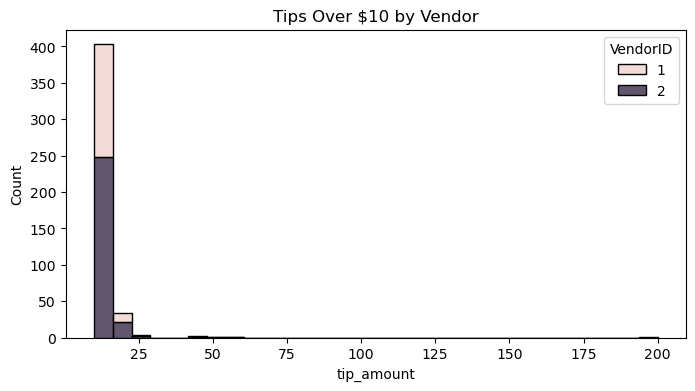

In [23]:
big_tips = df[df['tip_amount'] > 10]
plt.figure(figsize=(8,4))
sns.histplot(data=big_tips, x='tip_amount', hue='VendorID', bins=30, multiple='stack')
plt.title('Tips Over $10 by Vendor')
plt.show()

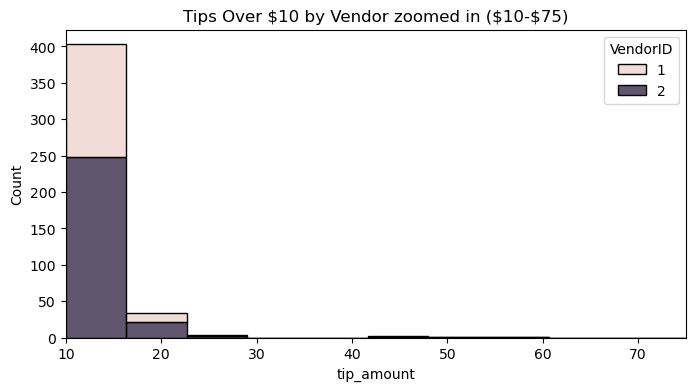

In [24]:
plt.figure(figsize=(8,4))
sns.histplot(data=big_tips, x='tip_amount', hue='VendorID', bins=30, multiple='stack')
plt.xlim(10,75)
plt.title('Tips Over $10 by Vendor zoomed in ($10-$75)')
plt.show()

### Passenger count

In [25]:
df['passenger_count'].value_counts().sort_index()

passenger_count
0       33
1    16117
2     3305
3      953
4      455
5     1143
6      693
Name: count, dtype: int64

Most trips (16,117 of 22,699) carry a single passenger.

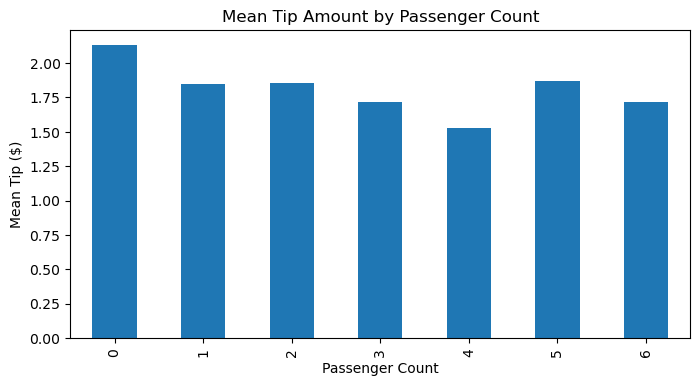

In [26]:
mean_tips_by_passenger = df.groupby('passenger_count')['tip_amount'].mean()
plt.figure(figsize=(8,4))
mean_tips_by_passenger.plot(kind='bar')
plt.title('Mean Tip Amount by Passenger Count')
plt.xlabel('Passenger Count')
plt.ylabel('Mean Tip ($)')
plt.show()

### Monthly and daily trends

In [27]:
monthly_rides = df['month'].value_counts().reindex(month_order)
monthly_rides

month
January      1997
February     1769
March        2049
April        2019
May          2013
June         1964
July         1697
August       1724
September    1734
October      2027
November     1843
December     1863
Name: count, dtype: int64

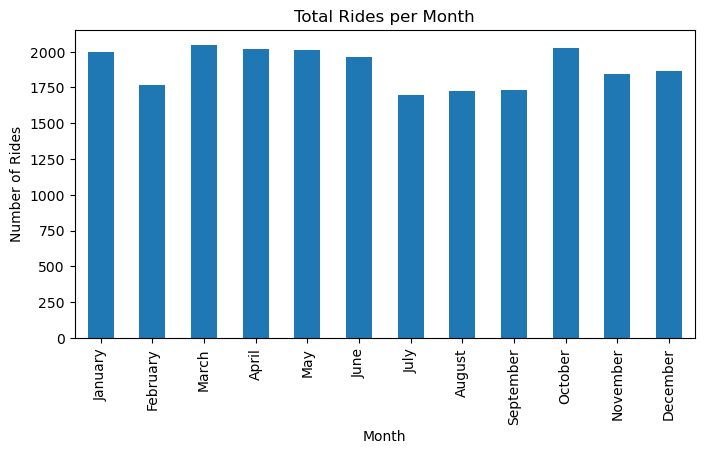

In [28]:
plt.figure(figsize=(8,4))
monthly_rides.plot(kind='bar')
plt.title('Total Rides per Month')
plt.xlabel('Month')
plt.ylabel('Number of Rides')
plt.show()

In [29]:
daily_rides = df['day'].value_counts().reindex(day_order)
daily_rides

day
Monday       2931
Tuesday      3198
Wednesday    3390
Thursday     3402
Friday       3413
Saturday     3367
Sunday       2998
Name: count, dtype: int64

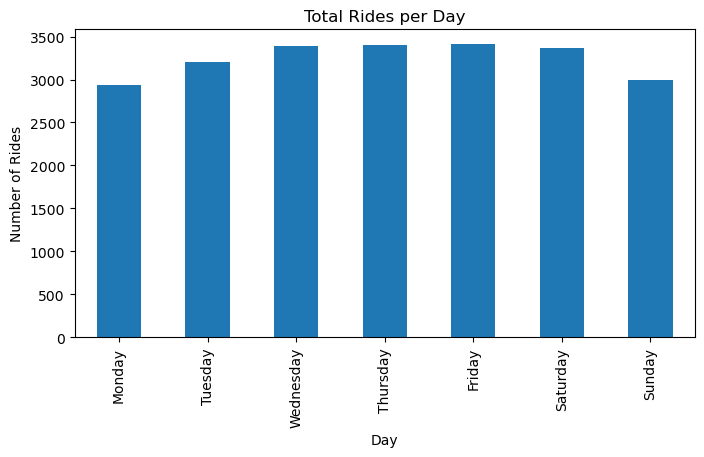

In [30]:
plt.figure(figsize=(8,4))
daily_rides.plot(kind='bar')
plt.title('Total Rides per Day')
plt.xlabel('Day')
plt.ylabel('Number of Rides')
plt.show()

Ride volume is fairly steady across months (March is highest at 2,049 rides, July lowest at 1,697). By weekday, Wednesday to Saturday are busiest and Monday and Sunday quietest.

In [31]:
revenue_by_day = df.groupby('day')['total_amount'].sum().reindex(day_order)
revenue_by_day

day
Monday       49574.37
Tuesday      52527.14
Wednesday    55310.47
Thursday     57181.91
Friday       55818.74
Saturday     51195.40
Sunday       48624.06
Name: total_amount, dtype: float64

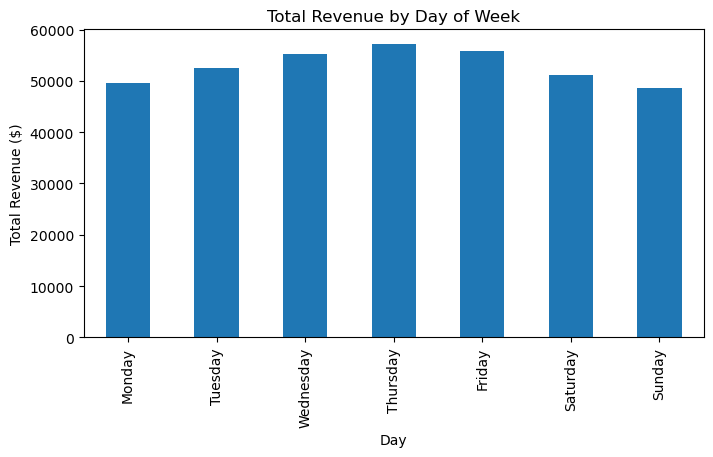

In [32]:
plt.figure(figsize=(8,4))
revenue_by_day.plot(kind='bar')
plt.title('Total Revenue by Day of Week')
plt.xlabel('Day')
plt.ylabel('Total Revenue ($)')
plt.show()

In [33]:
revenue_by_month = df.groupby('month')['total_amount'].sum().reindex(month_order)
revenue_by_month

month
January      31735.25
February     28937.89
March        33085.89
April        32012.54
May          33828.58
June         32920.52
July         26617.64
August       27759.56
September    28206.38
October      33065.83
November     30800.44
December     31261.57
Name: total_amount, dtype: float64

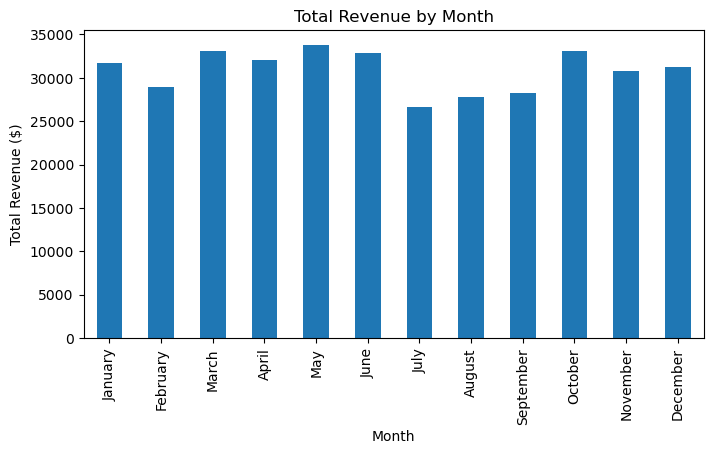

In [34]:
plt.figure(figsize=(8,4))
revenue_by_month.plot(kind='bar')
plt.title('Total Revenue by Month')
plt.xlabel('Month')
plt.ylabel('Total Revenue ($)')
plt.show()

Revenue follows ride volume: Thursday is the highest-earning weekday and Sunday the lowest, and July is the weakest month.

### Trip distance by drop-off location

In [35]:
df['DOLocationID'].nunique()

216

In [36]:
mean_distance_by_dropoff = df.groupby('DOLocationID')['trip_distance'].mean().sort_values(ascending=False)
mean_distance_by_dropoff

DOLocationID
23     24.275000
29     21.650000
210    20.500000
11     17.945000
51     17.310000
         ...    
137     1.818852
234     1.727806
237     1.555494
193     1.390556
207     1.200000
Name: trip_distance, Length: 216, dtype: float64

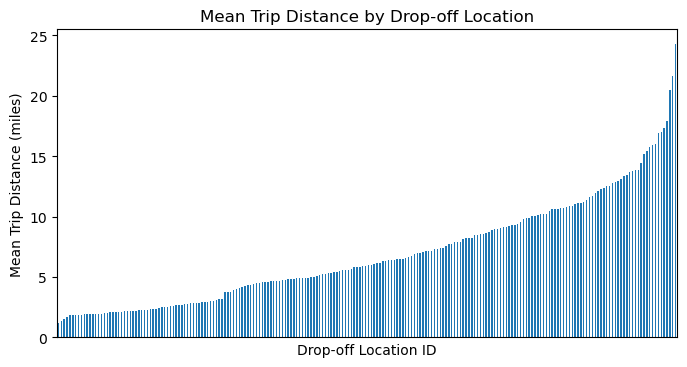

In [37]:
plt.figure(figsize=(8,4))
mean_distance_by_dropoff.sort_values(ascending=True).plot(kind='bar')
plt.title('Mean Trip Distance by Drop-off Location')
plt.xlabel('Drop-off Location ID')
plt.ylabel('Mean Trip Distance (miles)')
plt.xticks([])
plt.show()

Across 216 drop-off locations, mean trip distance ranges from about 1.2 miles to about 24.3 miles, so a small number of destinations are much farther than the typical trip.

## 5. Hypothesis test: credit card vs cash fares

- **H0:** mean fare amount is the same for credit card (payment_type 1) and cash (payment_type 2) trips.
- **H1:** the mean fare amounts differ.
- **Significance level:** 5%.
- **Method:** two-sample Welch's t-test (`equal_var=False`), which does not assume equal variances in the two groups.

The test is run on the cleaned data, and also on the uncleaned data for comparison.

In [38]:
df.groupby('payment_type')['fare_amount'].mean()

payment_type
1    13.429748
2    12.213546
3    12.186116
4     9.913043
Name: fare_amount, dtype: float64

In [39]:
def compare_fares(data, label):
    credit_card = data[data['payment_type'] == 1]['fare_amount']
    cash = data[data['payment_type'] == 2]['fare_amount']
    result = stats.ttest_ind(a=credit_card, b=cash, equal_var=False)
    decision = 'reject H0' if result.pvalue < 0.05 else 'fail to reject H0'
    print(label)
    print(f"  mean fare: credit card ${credit_card.mean():.2f} (n={len(credit_card):,}) | cash ${cash.mean():.2f} (n={len(cash):,})")
    print(f"  difference: ${credit_card.mean() - cash.mean():.2f}")
    print(f"  t = {result.statistic:.3f}, p = {result.pvalue:.2e} -> {decision} at the 5% level\n")

compare_fares(df_clean, "Cleaned data")
compare_fares(df, "Uncleaned data (for comparison)")

Cleaned data
  mean fare: credit card $13.34 (n=15,177) | cash $12.18 (n=7,197)
  difference: $1.16
  t = 7.042, p = 1.96e-12 -> reject H0 at the 5% level

Uncleaned data (for comparison)
  mean fare: credit card $13.43 (n=15,265) | cash $12.21 (n=7,267)
  difference: $1.22
  t = 6.867, p = 6.80e-12 -> reject H0 at the 5% level



**Result:** credit card trips averaged $13.34 against $12.18 for cash, a difference of $1.16. Welch's t-test gave t = 7.04 and p ≈ 1.96e-12, so we reject H0 at the 5% level: credit card and cash fares differ by more than chance would explain. Cleaning the data barely changed the result (a $1.22 difference before cleaning), so the finding does not depend on the removed records.

**Practical size:** the gap is about $1.16 per trip, small next to an average fare of around $13. It is statistically significant because the sample is large (over 22,000 trips), but its business impact is modest.

**Limitations:** this is observational data, so it shows an association, not a cause. The test does not control for trip distance or duration, which also drive the fare. A regression that includes distance would be a sensible next step.